__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using raw data form three independent experiments in Gilbert Lab:
      1. MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
      2. DDRi screen by Tom (unpublished)
      3. DDRi screen by Shaheen (unpublished)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [x] Compare with ScreenProcessing
<!-- - [ ] Test Command Line Interface (CLI) for the pipeline -->

___
    Thu Mar  7 03:55:05 UTC 2024

I have implmented all required features for single-guide and dual-guide designs. Here I want to perform enough tests to make sure I have everything ready to go for other users!
___
    Sun May 12 02:17:52 UTC 2024

I have performed multiple rounds of sanity checks and tests. Then I changed codes in ScreenPro2 accordingly. ScreenPro2 v0.3.0 should be ready to go for other users!

In [1]:
!pip uninstall -y screenpro2
!pip install git+https://github.com/arcinstitute/screenpro2.git@cli
# !pip install git+https://github.com/arcinstitute/screenpro2.git
# pip install screenpro2

Found existing installation: ScreenPro2 0.3.0
Uninstalling ScreenPro2-0.3.0:
  Successfully uninstalled ScreenPro2-0.3.0
  Cloning https://github.com/arcinstitute/screenpro2.git (to revision cli) to /tmp/pip-req-build-x9ie9yw7
  Running command git clone --filter=blob:none --quiet https://github.com/arcinstitute/screenpro2.git /tmp/pip-req-build-x9ie9yw7
  Running command git checkout -b cli --track origin/cli
  Switched to a new branch 'cli'
  branch 'cli' set up to track 'origin/cli'.
  Resolved https://github.com/arcinstitute/screenpro2.git to commit d282e8ae82cae9136d2130bc087809c0461a8889
  Preparing metadata (setup.py) ... done
  Created wheel for ScreenPro2: filename=ScreenPro2-0.3.0-py3-none-any.whl size=29449 sha256=c6a06b1fe5374476ccfaf723cf8e060f1665003eff7c8b3ff55291b38c51fcea
  Stored in directory: /tmp/pip-ephem-wheel-cache-87qfy90x/wheels/07/df/62/0c40d53ae17617e83ca0ebb6556a82eb7019e8e8c4f8c45a98
Successfully built ScreenPro2


In [2]:
import os
import subprocess 

import numpy as np
import pandas as pd
import polars as pl
import biobear as bb
import anndata as ad
import matplotlib.pyplot as plt

from time import time
from glob import glob

import screenpro as scp

In [3]:
def write_pkl(d, name):
    file_name = f'{name}.pkl'
    with open(file_name, 'wb') as file:
        pickle.dump(d, file)
        print(f'Object successfully saved to "{file_name}"')

def read_pkl(name):
    file_name = f'{name}.pkl'
    with open(file_name, 'rb') as f:
        d = pickle.load(f)
    return d

# Collect data
A Minimum Viable Data (MVD)!

In [4]:
# %%bash 
# mkdir -p DDRi_PRDX1_screens_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v3/DDRi-PRDX1-screens/`; do
#     b=`basename $fq`;
#     echo $b;
#     gsutil cp $fq DDRi_PRDX1_screens_fastq/$b;
# done

In [5]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

In [6]:
!screenpro counter --help

usage: screenpro counter [-h] [-c CAS_TYPE] [--single-guide-design]
                         [--dual-guide-design] -l LIBRARY [-s SAMPLE_SHEET]
                         [-o OUTPUT]

Process FASTQ files to count sgRNA sequences.

optional arguments:
  -h, --help            show this help message and exit
  -c CAS_TYPE, --cas-type CAS_TYPE
                        Type of Cas protein used for the screen. Default: cas9
  --single-guide-design
                        Single guide design library.
  --dual-guide-design   Dual guide design library.
  -l LIBRARY, --library LIBRARY
                        Path to library file.
  -s SAMPLE_SHEET, --sample_sheet SAMPLE_SHEET
                        Path to sample sheet.
  -o OUTPUT, --output OUTPUT
                        Path to output directory.


In [7]:
# !screenpro counter \
#     --single-guide-design \
#     -s 

## CRISPRi_v3

In [8]:
counter = scp.Counter(cas_type = 'cas9', library_type = 'dual_guide_design')

In [9]:
counter.load_library('JR_V3lib_top2_v2.csv', sep = ',', verbose = True)

Trimming protospacer sequences in 'protospacer_B' column.
Library table successfully loaded.


In [10]:
samples = [
    os.path.basename(fq).split('_R1')[0] 
    for fq in glob('DDRi_PRDX1_screen/fastq/*R1.fastq.gz')
]
samples.sort()

In [11]:
help(counter.get_counts_matrix)

Help on method get_counts_matrix in module screenpro.ngs.counter:

get_counts_matrix(fastq_dir, samples, get_recombinant=False, cas_type='cas9', protospacer_length='auto', trim_first_g=False, write=True, parallel=False, verbose=False) method of screenpro.ngs.counter.Counter instance
    Get count matrix for given samples



In [12]:
counter.get_counts_matrix(
    fastq_dir = 'DDRi_PRDX1_screen/fastq',
    samples = ['i01'],#samples,
    get_recombinant=False,
    verbose = True
)

i01
count file exists ...
% mapped reads 67.22400750620561


In [13]:
# meta = pd.read_excel('DDRi_PRDX1_screen/PRDX1samplesheet_incgrowth.xlsx').set_index('index')

In [15]:
adata = counter.build_counts_anndata(source='library')
# adata.obs = meta

In [ ]:
# adata.var['targetType'] = ''
# adata.var.loc[adata.var.target.eq('negative_control'),'targetType']  = 'negCtrl'
# adata.var.loc[~adata.var.target.eq('negative_control'),'targetType'] = 'gene'
# adata.var.index.name = None

# adata.obs.treatment = adata.obs.treatment.str.replace('-','T0')
# adata.obs = adata.obs.rename(columns={'treatment':'condition','rep':'replicate'})

# adata.obs['pop_doublings'] = meta['pop doublings'].replace('-',np.nan).astype(float)

# del adata.obs['pop doublings']

In [16]:
# adata.write_h5ad("DDRi_PRDX1_screen/adata.h5ad.gz",compression='gzip')

___

In [17]:
adata_old = ad.read_h5ad('DDRi_PRDX1_screen/old_adata_counts.h5ad.gz')

In [18]:
# adata_old.to_df().T[['i01']].index.str.split('++')

In [19]:
i01_screenpro2_count = adata.to_df().T[['i01']]

In [20]:
i01_old_count = adata_old.to_df().T[['i01']].rename(columns={'i01':'i01_old'})

i01_old_count.index = i01_old_count.index.str.split('\+\+').str[1]

In [21]:
i01_ol_df = pd.concat([
    i01_old_count,
    i01_screenpro2_count
    ]
,axis=1)

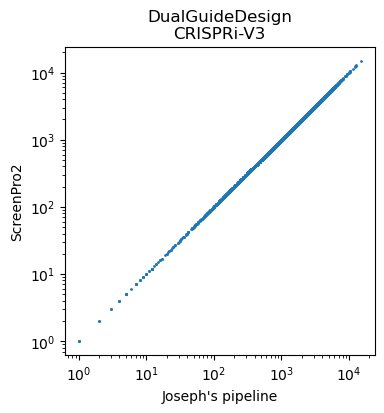

In [22]:
fig, ax = plt.subplots(figsize=(4,4))

i01_ol_df.plot.scatter('i01_old','i01',s=1, ax=ax)

plt.xlabel("Joseph's pipeline")
plt.ylabel('ScreenPro2')

plt.xscale('log')
plt.yscale('log')

plt.title('DualGuideDesign\nCRISPRi-V3')

plt.show()

___

In [23]:
# fig, axes = plt.subplots(ncols=5,
#                          figsize=(13,3), 
#                          gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
#                          # sharey=True
#                         )
# scp.pl.plotReplicateScatter(axes[0], adata, 'i01','i02','T0',min_val=0,max_val=10)
# scp.pl.plotReplicateScatter(axes[1], adata, 'i03','i04','vehicle',min_val=0,max_val=10)
# scp.pl.plotReplicateScatter(axes[2], adata, 'i03','i05','vehicle',min_val=0,max_val=10)
# scp.pl.plotReplicateScatter(axes[3], adata, 'i06','i07','DNAPKi',min_val=0,max_val=10)
# scp.pl.plotReplicateScatter(axes[4], adata, 'i06','i08','DNAPKi',min_val=0,max_val=10)

# fig.suptitle('PRDX1 parent screen',fontsize=15)

# # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
# plt.show()


___

In [24]:
# adata_PRDX1KO = adata[adata.obs['cell line'].eq('PRDX1KO')].copy()
# adata_parent  = adata[adata.obs['cell line'].eq('parent')].copy()

In [25]:
# screen0 = scp.PooledScreens(adata_parent)
# screen = scp.PooledScreens(adata_parent[adata_parent.obs.replicate.isin([1,2])].copy(),n_reps=2)

In [26]:
# screen.calculateDrugScreen(
#     t0='T0', untreated='vehicle', treated='DNAPKi',
#     db_untreated = 7.8,
#     db_treated = 7.5,
#     score_level='compare_reps'
# )


In [27]:
# screen.pdata

In [28]:
# fig, axes = plt.subplots(ncols=2,
#                          figsize=(5,3), 
#                          gridspec_kw={'wspace': 0.5, 'left': 0.12,'top':.8,'bottom':.3}, 
#                          # sharey=True
#                         )
# scp.pl.plotReplicateScatter(axes[0], screen.pdata, 'gamma_replicate_1','gamma_replicate_2','gamma',max_val=1)
# scp.pl.plotReplicateScatter(axes[1], screen.pdata, 'tau_replicate_1','tau_replicate_2','tau',max_val=1)


# fig.suptitle('PRDX1 parent screen',fontsize=15)

# # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
# plt.show()

In [29]:
# scp.utils.find_low_counts(screen0.adata)

In [30]:
# sel = ['target','score','ttest pvalue']# BH adj_pvalue # ttest pvalue
# gamma = screen.phenotypes['compare_reps']['gamma:vehicle_vs_T0'].loc[:,sel].reset_index(drop=True)

# tau = screen.phenotypes['compare_reps']['tau:DNAPKi_vs_T0'].loc[:,sel].reset_index(drop=True)

# rho = screen.phenotypes['compare_reps']['rho:DNAPKi_vs_vehicle'].loc[:,sel].reset_index(drop=True)

In [31]:
# # Create subplots and specify the size
# fig, (ax1,ax2,ax3) = plt.subplots(1,3,figsize=(4, 1.8))

# scp.pl.plot_volcano(ax1, gamma,threshold=5,xlim_l=-2, xlim_r=1,ctrl_label='negative_control')
# ax1.grid(False)
# ax1.get_legend().remove()
# ax1.set_title('gamma')

# scp.pl.plot_volcano(ax2, tau,threshold=5,xlim_l=-2, xlim_r=2,ctrl_label='negative_control')
# scp.pl.label_sensitivity_hit(ax2,tau,'PRDX1',threshold=5,size=5,size_txt=6,t_x=-.6,t_y=.2,ctrl_label='negative_control')

# ax2.grid(False)
# ax2.get_legend().remove()
# ax2.set_title('tau')

# scp.pl.plot_volcano(ax3, rho,threshold=5,xlim_l=-20, xlim_r=20,ctrl_label='negative_control')
# # label_resistance_hit(ax2,rho,'TTC1',size=5,size_txt=6,t_x=.1)
# # label_sensitivity_hit(ax2,rho,'CLHC1',size=5,size_txt=6,t_y=.1)

# ax3.grid(False)
# ax3.get_legend().remove()
# ax3.set_title('rho')


# for ax in [ax1,ax2,ax3]:
#     for item in ([ax.title, ax.xaxis.label, ax.yaxis.label] + ax.get_xticklabels() + ax.get_yticklabels()):
#         item.set_fontsize(6)

# fig.suptitle('PRDX1 parent screen',fontsize=9)
# plt.tight_layout()
# # Show the plot
# plt.show()

### 

## CRISPRi_v2

### Count FASTQ ...

- Compare counts with ScreenProcessing

In [ ]:
CRISPRi_v2_human_path = '../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz'

In [ ]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [ ]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

#### dataset1

In [43]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

In [32]:
samples = []
for fq_file in glob('molm13_exp_fastq/*.fastq.gz'):
    sample_id = fq_file.split('/')[1].replace('.fastq.gz','')
    # sample_id = fq_file.split('/')[1].split('.')[0].split('_S')[0]
    samples.append(sample_id)
samples

['DMSO_Rep2', 'DAC_Rep1', 'T0_Rep1', 'DAC_Rep2', 'DMSO_Rep1', 'T0_Rep2']

___
Without trimming first G:

In [39]:
counter = scp.ngs.Counter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=20)

Library table successfully loaded.


In [40]:
counter.get_counts_matrix(
    fastq_dir = 'molm13_exp_fastq/',
    samples = ['DAC_Rep2'],#samples,
    # trim_first_g=True,
    trim_first_g=False,
    write = 'force',
    verbose = True
)

DAC_Rep2
count file exists ...
skip loading count file, force write is set ...
done in 57.991s
count file written ...
% mapped reads 92.45927925994773


In [41]:
adata = counter.build_counts_anndata()

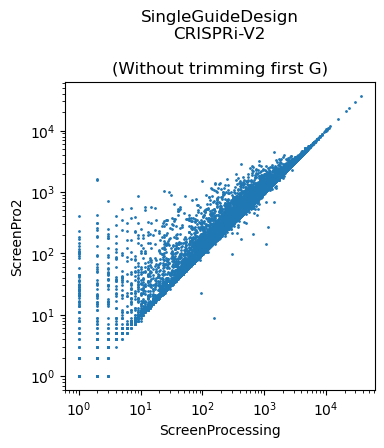

In [47]:
fig, ax = plt.subplots(figsize=(4,4))

pd.concat({
    'ScreenProcessing':screenprocessing_counts['DAC']['Rep2'], 
    'ScreenPro2':adata.to_df().loc['DAC_Rep2',screenprocessing_counts.index]
},axis=1).plot.scatter('ScreenProcessing','ScreenPro2',s=1,ax=ax)

plt.xscale('log')
plt.yscale('log')
plt.title('SingleGuideDesign\nCRISPRi-V2\n\n(Without trimming first G)')
plt.show()

___
With trimming first G:

In [48]:
counter = scp.ngs.Counter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=19)

Trimming protospacer sequences in 'protospacer' column.
Library table successfully loaded.


In [49]:
counter.get_counts_matrix(
    fastq_dir = 'molm13_exp_fastq/',
    samples = ['DAC_Rep2'],#samples,
    trim_first_g=True,
    write = 'force',
    verbose = True
)

DAC_Rep2
count file exists ...
skip loading count file, force write is set ...
done in 59.721s
count file written ...
% mapped reads 92.70175728442209


In [50]:
adata = counter.build_counts_anndata()

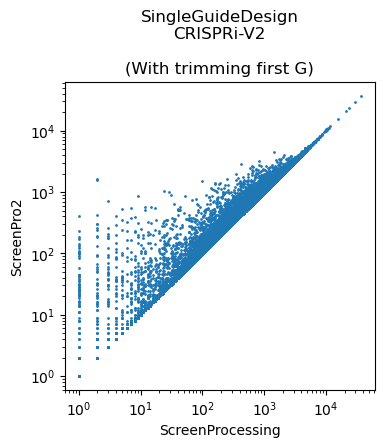

In [51]:
fig, ax = plt.subplots(figsize=(4,4))

pd.concat({
    'ScreenProcessing':screenprocessing_counts['DAC']['Rep2'], 
    'ScreenPro2':adata.to_df().loc['DAC_Rep2',screenprocessing_counts.index]
},axis=1).plot.scatter('ScreenProcessing','ScreenPro2',s=1,ax=ax)

plt.xscale('log')
plt.yscale('log')
plt.title('SingleGuideDesign\nCRISPRi-V2\n\n(With trimming first G)')
plt.show()

This is an interesting observation. I will need to investigate this further though looking into a different dataset.

#### dataset2

In [55]:
screenprocessing_counts = pd.read_csv(
    'DDRi_main_screens/PiKiMiRiWi_2reps_mergedcountstable.txt',
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

___
With trimming first G:

In [62]:
counter = scp.ngs.Counter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=19)

Trimming protospacer sequences in 'protospacer' column.
Library table successfully loaded.


In [64]:
counter.get_counts_matrix(
    fastq_dir = 'DDRi_main_screens/fastq/',
    samples = ['DMSO_1i'],#samples,
    trim_first_g=True,
    write = 'force',
    verbose = True
)

DMSO_1i
done in 33.572s
count file written ...
% mapped reads 91.94268243180207


In [65]:
adata = counter.build_counts_anndata()

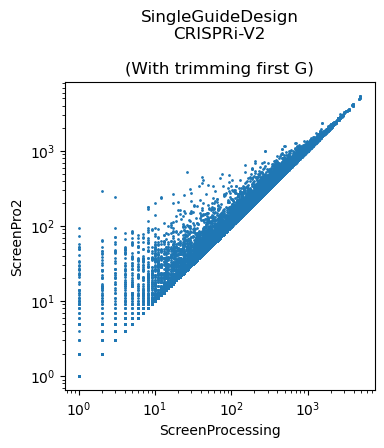

In [66]:
fig, ax = plt.subplots(figsize=(4,4))

pd.concat({
    'ScreenProcessing':screenprocessing_counts['DMSO']['rep1'],
    'ScreenPro2':adata.to_df().loc['DMSO_1i',screenprocessing_counts.index]
},axis=1).plot.scatter('ScreenProcessing','ScreenPro2',s=1,ax=ax)

plt.xscale('log')
plt.yscale('log')
plt.title('SingleGuideDesign\nCRISPRi-V2\n\n(With trimming first G)')
plt.show()

# 

In [67]:
%load_ext watermark
%watermark
%watermark --iversions

Last updated: 2024-05-12T02:14:46.591342+00:00

Python implementation: CPython
Python version       : 3.9.18
IPython version      : 8.15.0

Compiler    : GCC 11.2.0
OS          : Linux
Release     : 6.1.0-21-cloud-amd64
Machine     : x86_64
Processor   : 
CPU cores   : 16
Architecture: 64bit

screenpro : 0.3.0
biobear   : 0.20.0
matplotlib: 3.6.2
polars    : 0.20.23
numpy     : 1.26.0
pandas    : 1.5.3
anndata   : 0.10.7

